# **KNN**

Basic Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   BMI     10 non-null     float64
 1   Age     10 non-null     int64  
 2   Sugar   10 non-null     int64  
dtypes: float64(1), int64(2)
memory usage: 372.0 bytes
None
Accuracy: 1.00
Prediction for new data: 1


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


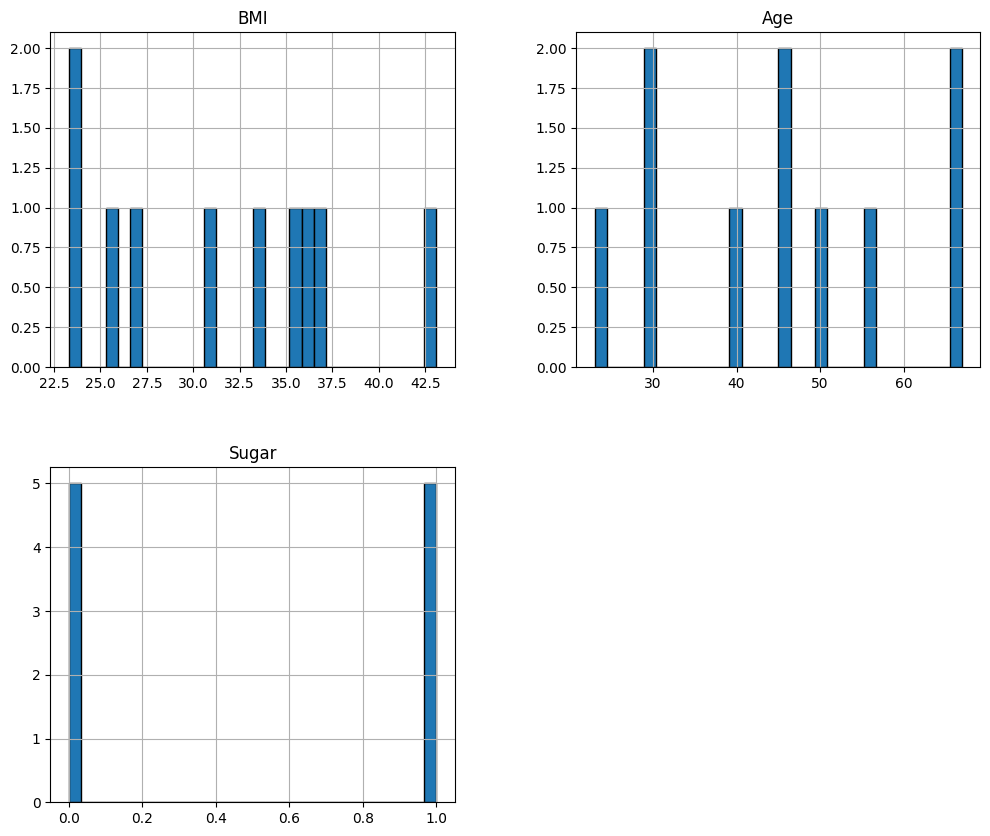

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Data
df = pd.DataFrame({
    "BMI":[33.6,26.6,23.4,43.1,35.3,35.9,36.7,25.7,23.3,31.0],
    "Age":[50,30,40,67,23,67,45,46,29,56],
    "Sugar":[1,0,0,0,1,1,1,0,0,1]
})

print("Basic Information:")
print(df.info())

df.hist(figsize=(12,10), bins=30, edgecolor="black")

# Input and output
X = df[["BMI","Age"]]
y = df["Sugar"]

# Split and scale
X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=.2,random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# KNN
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train,y_train)

# Prediction
pred = knn.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test,pred):.2f}")

# New data
new = scaler.transform([[43.6,40]])
print("Prediction for new data:",knn.predict(new)[0])

# **KMeans**

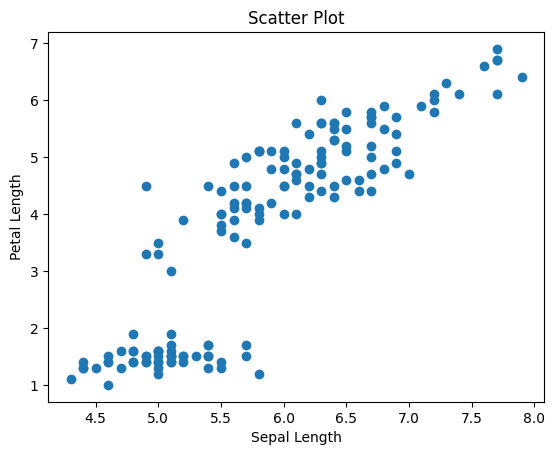

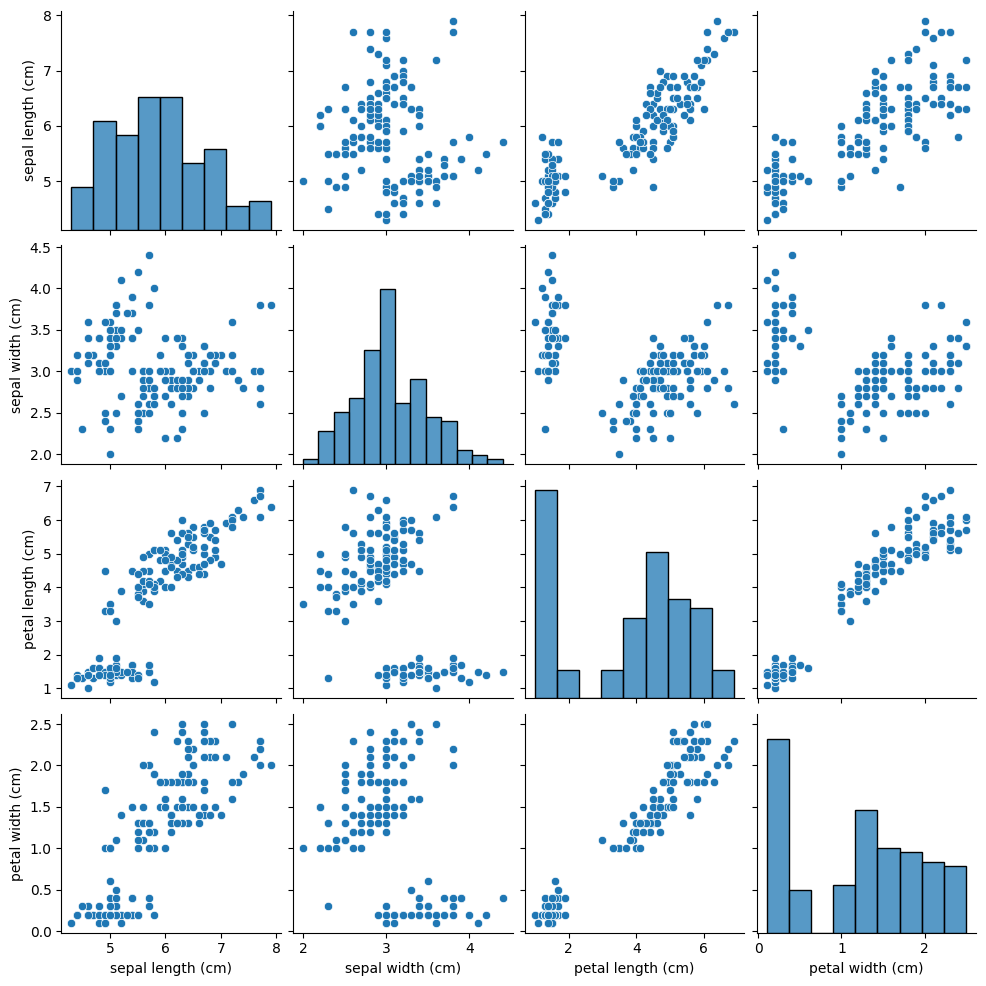

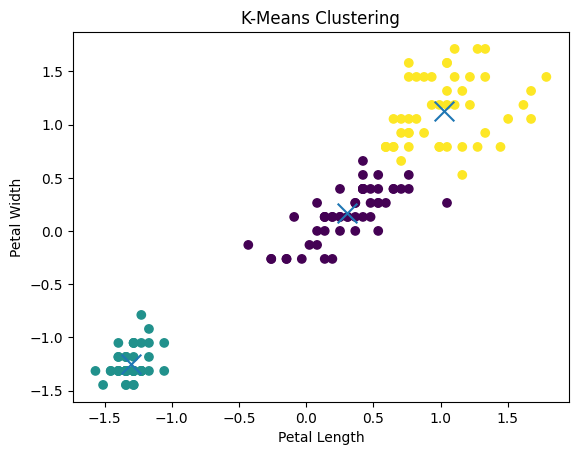

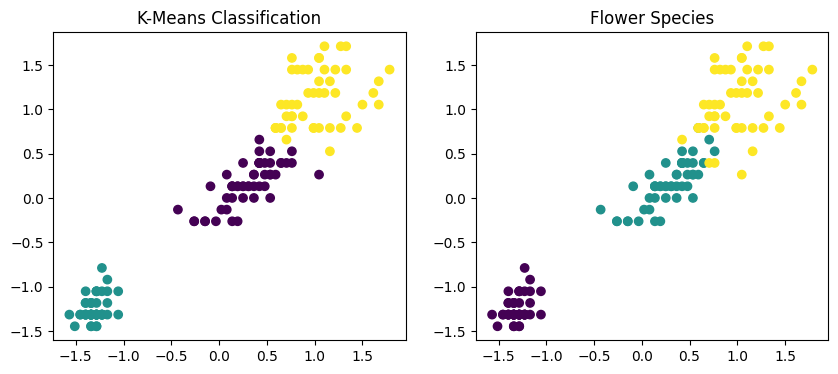

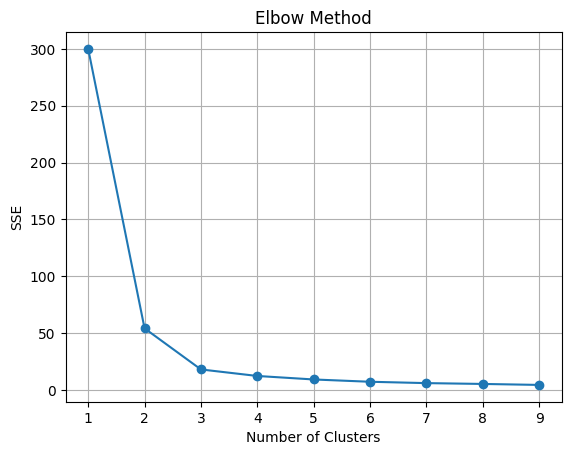

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Load Iris data
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["flower"] = iris.target

# 1. Scatter plot
plt.scatter(df.iloc[:,0],df.iloc[:,2])
plt.xlabel("Sepal Length"); plt.ylabel("Petal Length")
plt.title("Scatter Plot"); plt.show()

# 2. Pair plot
sns.pairplot(df.iloc[:,:4])
plt.show()

# Petal length & width + scaling
X = StandardScaler().fit_transform(df.iloc[:,2:4])

# 3. K-Means
km = KMeans(3,random_state=1,n_init=10)
labels = km.fit_predict(X)

plt.scatter(X[:,0],X[:,1],c=labels)
plt.scatter(km.cluster_centers_[:,0],km.cluster_centers_[:,1],
            marker="x",s=200)
plt.xlabel("Petal Length"); plt.ylabel("Petal Width")
plt.title("K-Means Clustering"); plt.show()

# 4. K-Means vs Actual
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.scatter(X[:,0],X[:,1],c=labels)
plt.title("K-Means Classification")

plt.subplot(1,2,2)
plt.scatter(X[:,0],X[:,1],c=df.flower)
plt.title("Flower Species")
plt.show()

# 5. Elbow method
sse = []
for k in range(1,10):
    sse.append(KMeans(k,random_state=1,n_init=10).fit(X).inertia_)

plt.plot(range(1,10),sse,marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("SSE")
plt.title("Elbow Method")
plt.grid()
plt.show()

# **DBSCAN**

make_moons dataset generated successfully!

Shape: (300, 2)

First 5 rows:
    Feature_1  Feature_2
0   0.622519  -0.372101
1   1.904269  -0.136303
2  -0.069431   0.456117
3   0.933899   0.237483
4   1.180360  -0.490847

Missing values:
 Feature_1    0
Feature_2    0
dtype: int64

Description:
         Feature_1   Feature_2
count  300.000000  300.000000
mean     0.500413    0.253196
std      0.871355    0.496069
min     -1.104663   -0.563235
25%     -0.063124   -0.197303
50%      0.485312    0.248550
75%      1.047578    0.713130
max      2.131198    1.107772


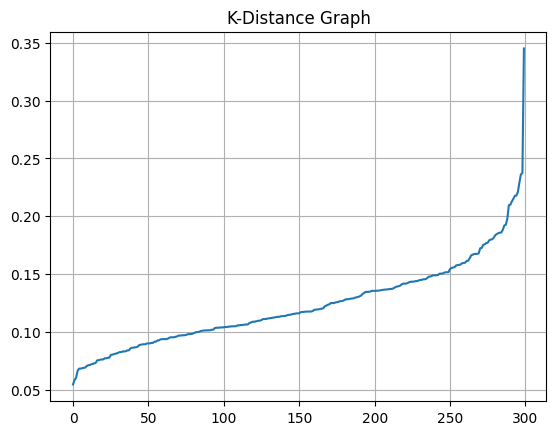


Cluster distribution:
 Cluster
 0    150
 1    148
-1      2
Name: count, dtype: int64

DBSCAN found 2 clusters and 2 noise points

Mean feature values:
          Feature_1  Feature_2
Cluster                      
0         1.004969  -0.128736
1         0.008472   0.643892


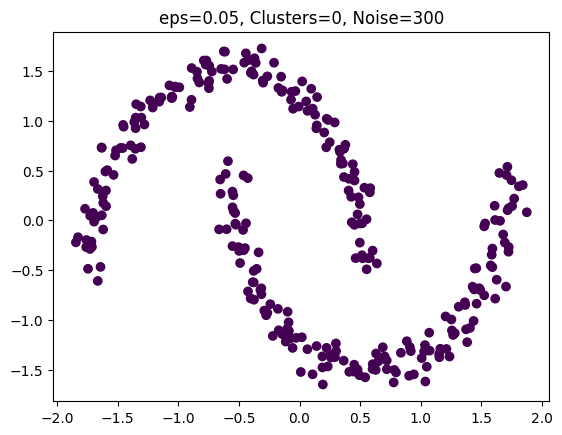

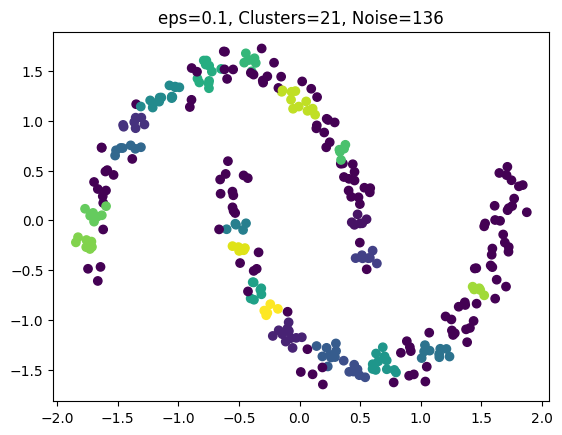

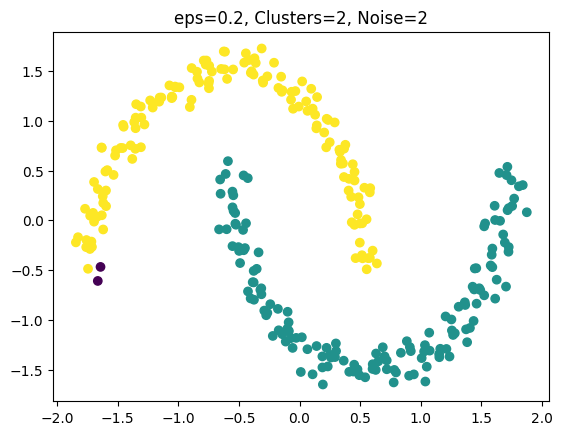

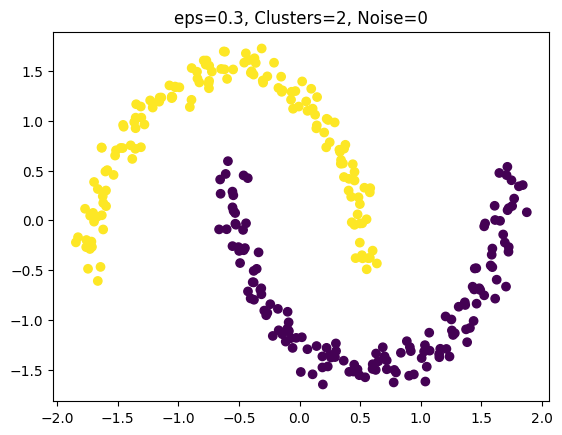

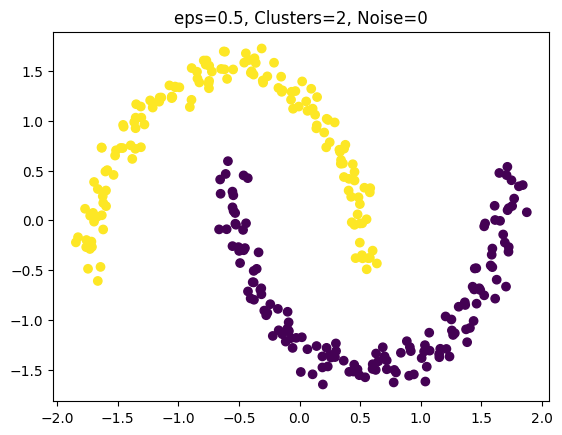

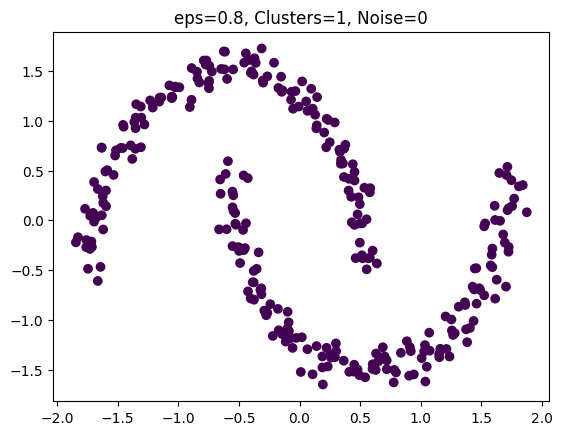

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

# Data
X,y=make_moons(300,noise=.05,random_state=42)
df=pd.DataFrame(X,columns=["Feature_1","Feature_2"])

print("make_moons dataset generated successfully!")
print("\nShape:",df.shape)
print("\nFirst 5 rows:\n",df.head())
print("\nMissing values:\n",df.isna().sum())
print("\nDescription:\n",df.describe())

# Scale
X=StandardScaler().fit_transform(X)

# K-distance graph
d=NearestNeighbors(n_neighbors=5).fit(X).kneighbors(X)[0][:,4]
plt.plot(np.sort(d))
plt.title("K-Distance Graph")
plt.grid()
plt.show()

# DBSCAN
labels=DBSCAN(eps=.2,min_samples=5).fit_predict(X)
df["Cluster"]=labels

print("\nCluster distribution:\n",df.Cluster.value_counts())
print("\nDBSCAN found",
      len(set(labels))-(-1 in labels),"clusters and",
      sum(labels==-1),"noise points")

# Cluster means
print("\nMean feature values:\n",
      df[df.Cluster!=-1].groupby("Cluster").mean())

# Different eps values
for e in [.05,.1,.2,.3,.5,.8]:
    l=DBSCAN(eps=e,min_samples=5).fit_predict(X)
    plt.figure()
    plt.scatter(X[:,0],X[:,1],c=l)
    plt.title(f"eps={e}, Clusters={len(set(l))-(-1 in l)}, Noise={sum(l==-1)}")
    plt.show()

# **PCA**

Feature Names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Original Data Shape:
(150, 4)

First 5 Rows:
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]

PCA RESULTS

Mean Values:
[5.84333333 3.05733333 3.758      1.19933333]

Covariance Matrix:
[[ 0.68569351 -0.042434    1.27431544  0.51627069]
 [-0.042434    0.18997942 -0.32965638 -0.12163937]
 [ 1.27431544 -0.32965638  3.11627785  1.2956094 ]
 [ 0.51627069 -0.12163937  1.2956094   0.58100626]]

Eigenvalues:
[4.22824171 0.24267075 0.0782095  0.02383509]

Selected Eigenvectors:
[[-0.36138659  0.65658877]
 [ 0.08452251  0.73016143]
 [-0.85667061 -0.17337266]
 [-0.3582892  -0.07548102]]

Reduced Data Shape:
(150, 2)

First 5 Rows of PCA Result:
[[ 2.68412563  0.31939725]
 [ 2.71414169 -0.17700123]
 [ 2.88899057 -0.14494943]
 [ 2.74534286 -0.31829898]
 [ 2.72871654  0.32675451]]

EXPLAINED VARIANCE
PC1: 92.46%
PC1 Cumulative: 92.46%
PC2: 5.31%
PC2 Cumu

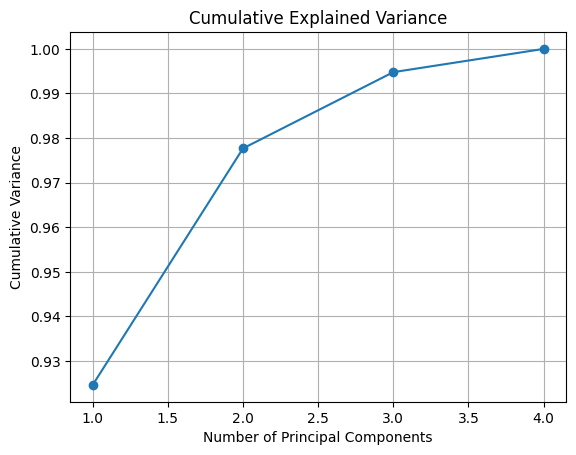

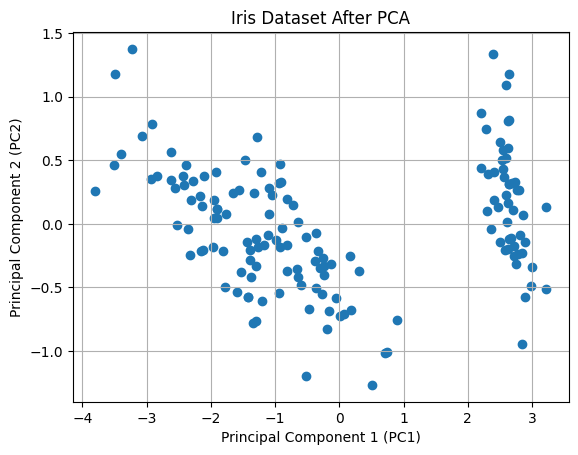

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

# Load data
iris = load_iris()
X = iris.data

print("Feature Names:")
print(iris.feature_names)
print("\nOriginal Data Shape:")
print(X.shape)
print("\nFirst 5 Rows:")
print(X[:5])

# Mean and center data
mean = np.mean(X, axis=0)
Xc = X - mean

# Covariance
cov = np.cov(Xc, rowvar=False)

# Eigenvalues and eigenvectors
values, vectors = np.linalg.eigh(cov)
i = np.argsort(values)[::-1]
values, vectors = values[i], vectors[:,i]

# Select 2 components
W = vectors[:, :2]
pca = Xc @ W

print("\nPCA RESULTS")
print("\nMean Values:")
print(mean)
print("\nCovariance Matrix:")
print(cov)
print("\nEigenvalues:")
print(values)
print("\nSelected Eigenvectors:")
print(W)
print("\nReduced Data Shape:")
print(pca.shape)
print("\nFirst 5 Rows of PCA Result:")
print(pca[:5])

# Explained variance
ratio = values / values.sum()
cum = np.cumsum(ratio)

print("\nEXPLAINED VARIANCE")
for i in range(len(ratio)):
    print(f"PC{i+1}: {ratio[i]*100:.2f}%")
    print(f"PC{i+1} Cumulative: {cum[i]*100:.2f}%")

# Explained variance plot
plt.plot(range(1,5), cum, marker="o")
plt.title("Cumulative Explained Variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Variance")
plt.grid()
plt.show()

# PCA result plot
plt.scatter(pca[:,0], pca[:,1])
plt.title("Iris Dataset After PCA")
plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.grid()
plt.show()

# **LOGISTIC REGRESSSION**

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
(8

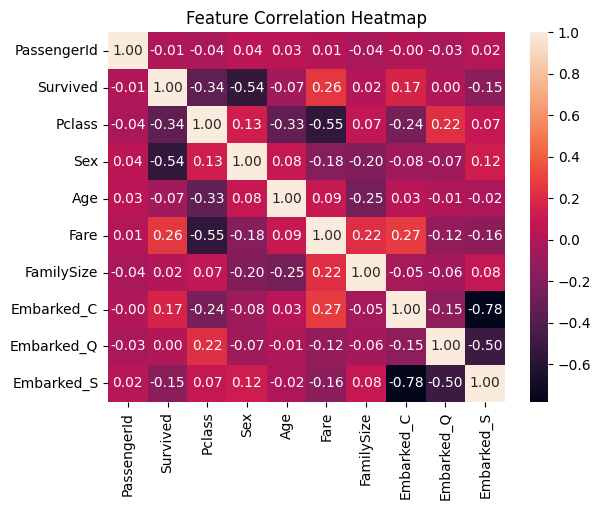


Accuracy: 0.7988826815642458
Precision: 0.7796610169491526
Recall: 0.6666666666666666
F1 Score: 0.71875


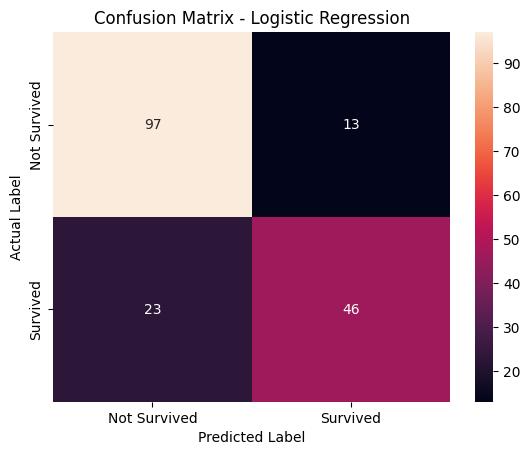


Misclassified Samples:
     PassengerId  Survived  Pclass  Sex        Age      Fare  FamilySize  \
553          554         1       3    1  22.000000    7.2250           1   
559          560         1       3    0  36.000000   17.4000           2   
279          280         1       3    0  35.000000   20.2500           3   
712          713         1       1    1  48.000000   52.0000           2   
455          456         1       3    1  29.000000    7.8958           1   
65            66         1       3    1  29.699118   15.2458           3   
489          490         1       3    1   9.000000   15.9000           3   
869          870         1       3    1   4.000000   11.1333           3   
165          166         1       3    1   9.000000   20.5250           3   
297          298         0       1    0   2.000000  151.5500           4   
564          565         0       3    0  29.699118    8.0500           1   
502          503         0       3    0  29.699118    7.6292    

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import *

# Load data
df = pd.read_csv("/content/Titanic-Dataset.csv")
print(df.head())
print(df.shape)
print(df.isnull().sum())

# Preprocessing
df["Age"] = SimpleImputer(strategy="mean").fit_transform(df[["Age"]]).ravel()
df["Embarked"] = SimpleImputer(strategy="most_frequent").fit_transform(df[["Embarked"]]).ravel()
df["Sex"] = df["Sex"].map({"female": 0, "male": 1})
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df = pd.get_dummies(df, columns=["Embarked"], dtype=int)
df.drop(columns=["Cabin", "Name", "Ticket", "SibSp", "Parch"], inplace=True)

# Correlation Heatmap
sns.heatmap(df.corr(), annot=True, fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

# Split X and y
X = df.drop(columns=["Survived", "PassengerId"])
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scaling
s = StandardScaler()
X_train = s.fit_transform(X_train)
X_test = s.transform(X_test)

# Logistic Regression
m = LogisticRegression()
m.fit(X_train, y_train)
y_pred = m.predict(X_test)

# Results
print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

# Confusion Matrix
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d",
            xticklabels=["Not Survived", "Survived"],
            yticklabels=["Not Survived", "Survived"])
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

# Misclassified Samples
r = df.loc[y_test.index].copy()
r["Predicted"] = y_pred
r = r[r["Survived"] != r["Predicted"]]

print("\nMisclassified Samples:")
print(r)
print("\nTotal Misclassified Samples:", len(r))


# **SVM**

First 5 Rows:
   Feature 1  Feature 2  Target
0   0.803926  -0.291407       1
1   2.314433  -0.122238       1
2  -0.280392   0.450938       1
3   0.789446   0.384060       0
4   1.186657  -0.511438       1

Shape: (300, 3)

Class Distribution:
Target
1    150
0    150
Name: count, dtype: int64


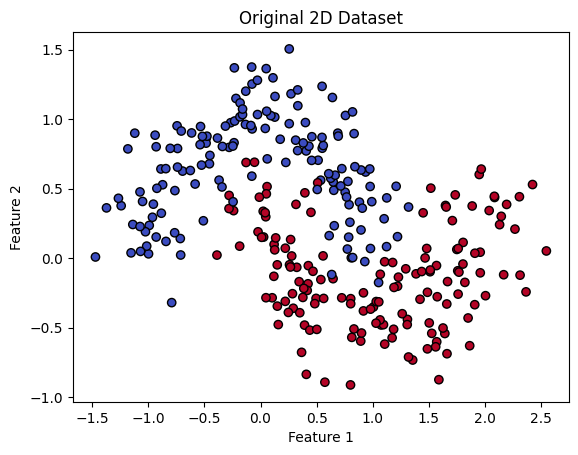


Model Accuracy
Linear SVM: 0.83
RBF SVM: 0.92

Linear SVM Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.76      0.82        45
           1       0.79      0.91      0.85        45

    accuracy                           0.83        90
   macro avg       0.84      0.83      0.83        90
weighted avg       0.84      0.83      0.83        90


RBF SVM Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.84      0.92        45
           1       0.87      1.00      0.93        45

    accuracy                           0.92        90
   macro avg       0.93      0.92      0.92        90
weighted avg       0.93      0.92      0.92        90


Number of Support Vectors:
Linear SVM: 66
RBF SVM: 53


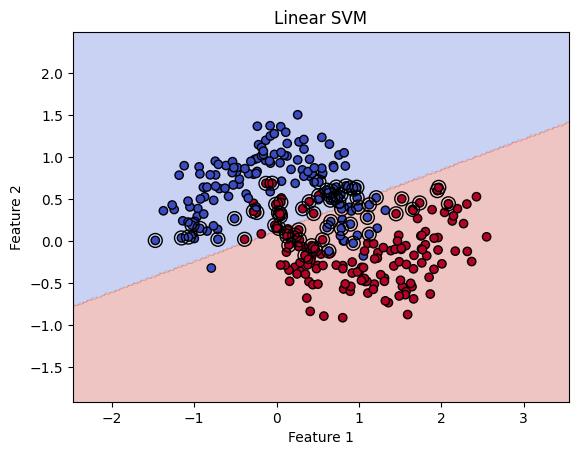

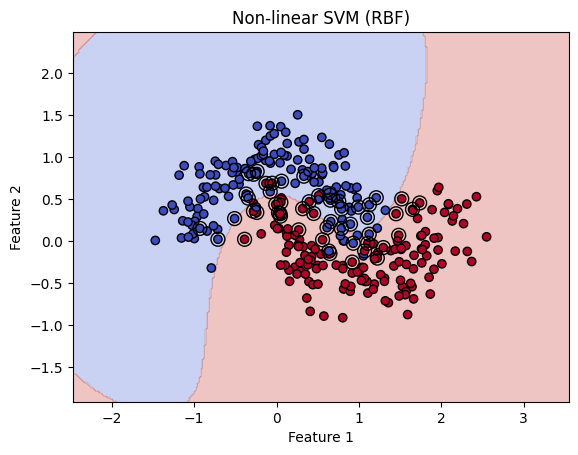

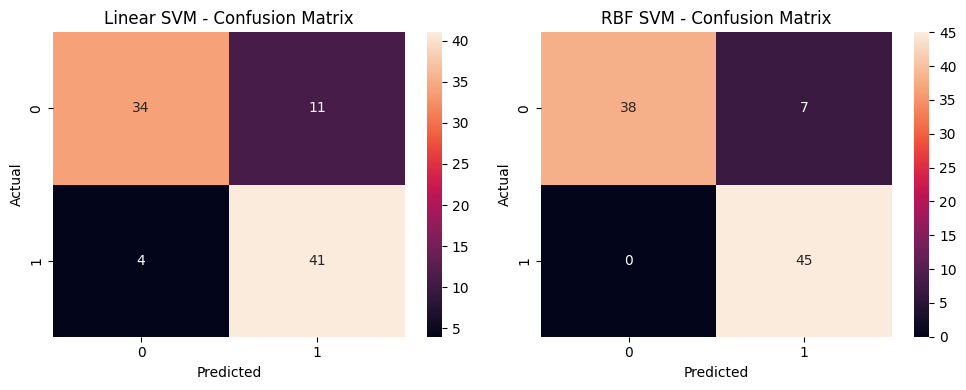


RBF SVM performs better than Linear SVM


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Data
X, y = make_moons(300, noise=0.2, random_state=42)
df = pd.DataFrame(X, columns=["Feature 1", "Feature 2"])
df["Target"] = y

print("First 5 Rows:")
print(df.head())
print("\nShape:", df.shape)
print("\nClass Distribution:")
print(df.Target.value_counts())

# Original Data
plt.scatter(X[:,0], X[:,1], c=y, cmap="coolwarm", edgecolors="k")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Original 2D Dataset")
plt.show()

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# SVM Models
linear = SVC(kernel="linear", C=1)
rbf = SVC(kernel="rbf", C=1, gamma="scale")

linear.fit(X_train, y_train)
rbf.fit(X_train, y_train)

# Predictions
p1 = linear.predict(X_test)
p2 = rbf.predict(X_test)

# Accuracy
print("\nModel Accuracy")
print("Linear SVM:", round(accuracy_score(y_test, p1), 2))
print("RBF SVM:", round(accuracy_score(y_test, p2), 2))

print("\nLinear SVM Classification Report:")
print(classification_report(y_test, p1))
print("\nRBF SVM Classification Report:")
print(classification_report(y_test, p2))

# Support Vectors
print("\nNumber of Support Vectors:")
print("Linear SVM:", len(linear.support_vectors_))
print("RBF SVM:", len(rbf.support_vectors_))

# Decision Boundaries
def plot_svm(model, title):
    x1, x2 = X[:,0].min()-1, X[:,0].max()+1
    y1, y2 = X[:,1].min()-1, X[:,1].max()+1
    xx, yy = np.meshgrid(np.arange(x1,x2,0.02),
                         np.arange(y1,y2,0.02))
    z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    plt.contourf(xx, yy, z, alpha=0.3, cmap="coolwarm")
    plt.scatter(X[:,0], X[:,1], c=y, cmap="coolwarm", edgecolors="k")
    plt.scatter(model.support_vectors_[:,0],
                model.support_vectors_[:,1],
                s=100, facecolors="none", edgecolors="black")
    plt.title(title)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.show()

plot_svm(linear, "Linear SVM")
plot_svm(rbf, "Non-linear SVM (RBF)")

# Confusion Matrices
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
sns.heatmap(confusion_matrix(y_test, p1), annot=True, fmt="d")
plt.title("Linear SVM - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.subplot(1,2,2)
sns.heatmap(confusion_matrix(y_test, p2), annot=True, fmt="d")
plt.title("RBF SVM - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

# Conclusion
if accuracy_score(y_test, p2) > accuracy_score(y_test, p1):
    print("\nRBF SVM performs better than Linear SVM")
elif accuracy_score(y_test, p1) > accuracy_score(y_test, p2):
    print("\nLinear SVM performs better than RBF SVM")
else:
    print("\nBoth SVM models have the same accuracy.")


# **DECISION TREE**

Original DataFrame:
     Weather Temperature    Wind Play
0      Sunny         Hot    Weak   No
1      Sunny         Hot  Strong   No
2   Overcast         Hot    Weak  Yes
3      Rainy        Mild    Weak  Yes
4      Rainy        Cool    Weak  Yes
5      Rainy        Cool  Strong   No
6   Overcast        Cool  Strong  Yes
7      Sunny        Mild    Weak   No
8      Sunny        Cool    Weak  Yes
9      Rainy        Mild    Weak  Yes
10     Sunny        Mild  Strong  Yes
11  Overcast        Mild  Strong  Yes
12  Overcast         Hot    Weak  Yes
13     Rainy        Mild  Strong   No

Shape: (14, 4)

Encoded Features:
   Weather_Rainy  Weather_Sunny  Temperature_Hot  Temperature_Mild  Wind_Weak
0              0              1                1                 0          1
1              0              1                1                 0          0
2              0              0                1                 0          1
3              1              0                0               

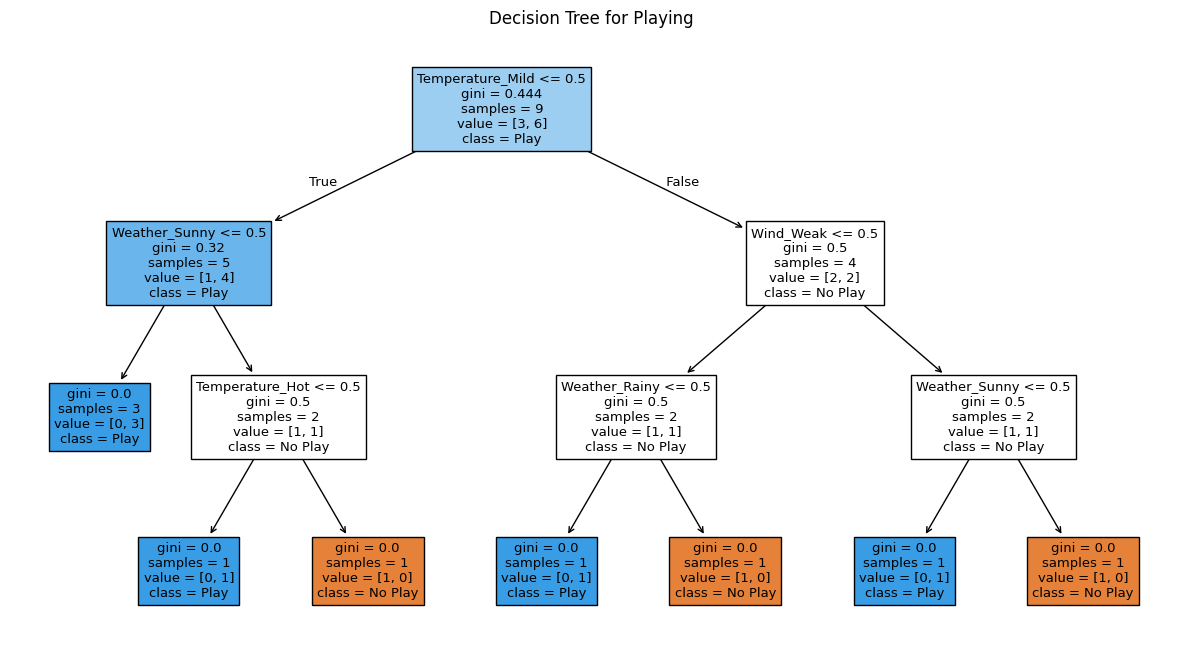

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

# Dataset
df = pd.DataFrame({
    "Weather":["Sunny","Sunny","Overcast","Rainy","Rainy","Rainy",
               "Overcast","Sunny","Sunny","Rainy","Sunny","Overcast",
               "Overcast","Rainy"],
    "Temperature":["Hot","Hot","Hot","Mild","Cool","Cool","Cool",
                   "Mild","Cool","Mild","Mild","Mild","Hot","Mild"],
    "Wind":["Weak","Strong","Weak","Weak","Weak","Strong","Strong",
            "Weak","Weak","Weak","Strong","Strong","Weak","Strong"],
    "Play":["No","No","Yes","Yes","Yes","No","Yes","No","Yes",
            "Yes","Yes","Yes","Yes","No"]
})

print("Original DataFrame:")
print(df)
print("\nShape:", df.shape)

# Encode Data
X = pd.get_dummies(df.drop("Play", axis=1), drop_first=True, dtype=int)
y = df["Play"].map({"No":0, "Yes":1})

print("\nEncoded Features:")
print(X.head())

# Split Data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print("\nTraining size:", len(X_train))
print("Testing size:", len(X_test))

# Decision Tree
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("\nAccuracy:", accuracy_score(y_test, y_pred))

# Plot Tree
plt.figure(figsize=(15,8))
plot_tree(model, filled=True, feature_names=X.columns,
          class_names=["No Play", "Play"])
plt.title("Decision Tree for Playing")
plt.show()


# **DECISION TREE WITH BAGGING,BOOSTING,RANDOM FOREST**

First 5 rows:
    mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter 

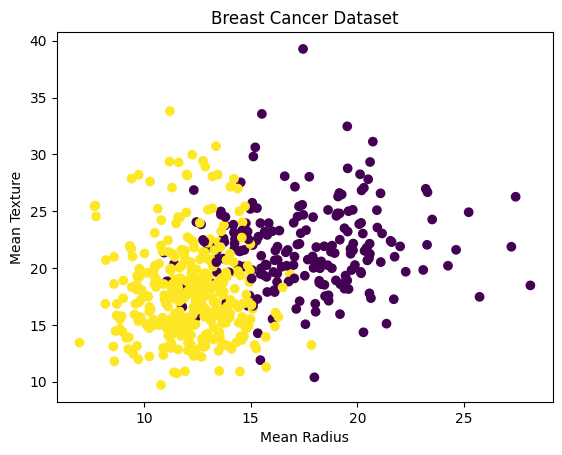


Training Shape: (455, 30)
Testing Shape: (114, 30)

 Decision Tree
Accuracy: 0.9385964912280702
              precision    recall  f1-score   support

           0       0.93      0.90      0.92        42
           1       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114


 Bagging
Accuracy: 0.9385964912280702
              precision    recall  f1-score   support

           0       0.93      0.90      0.92        42
           1       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114


 Boosting
Accuracy: 0.956140350877193
              precision    recall  f1-score   support

           0       0.97      0.90      0.94        42
           1       0.95      0.99      0.97        72

    acc

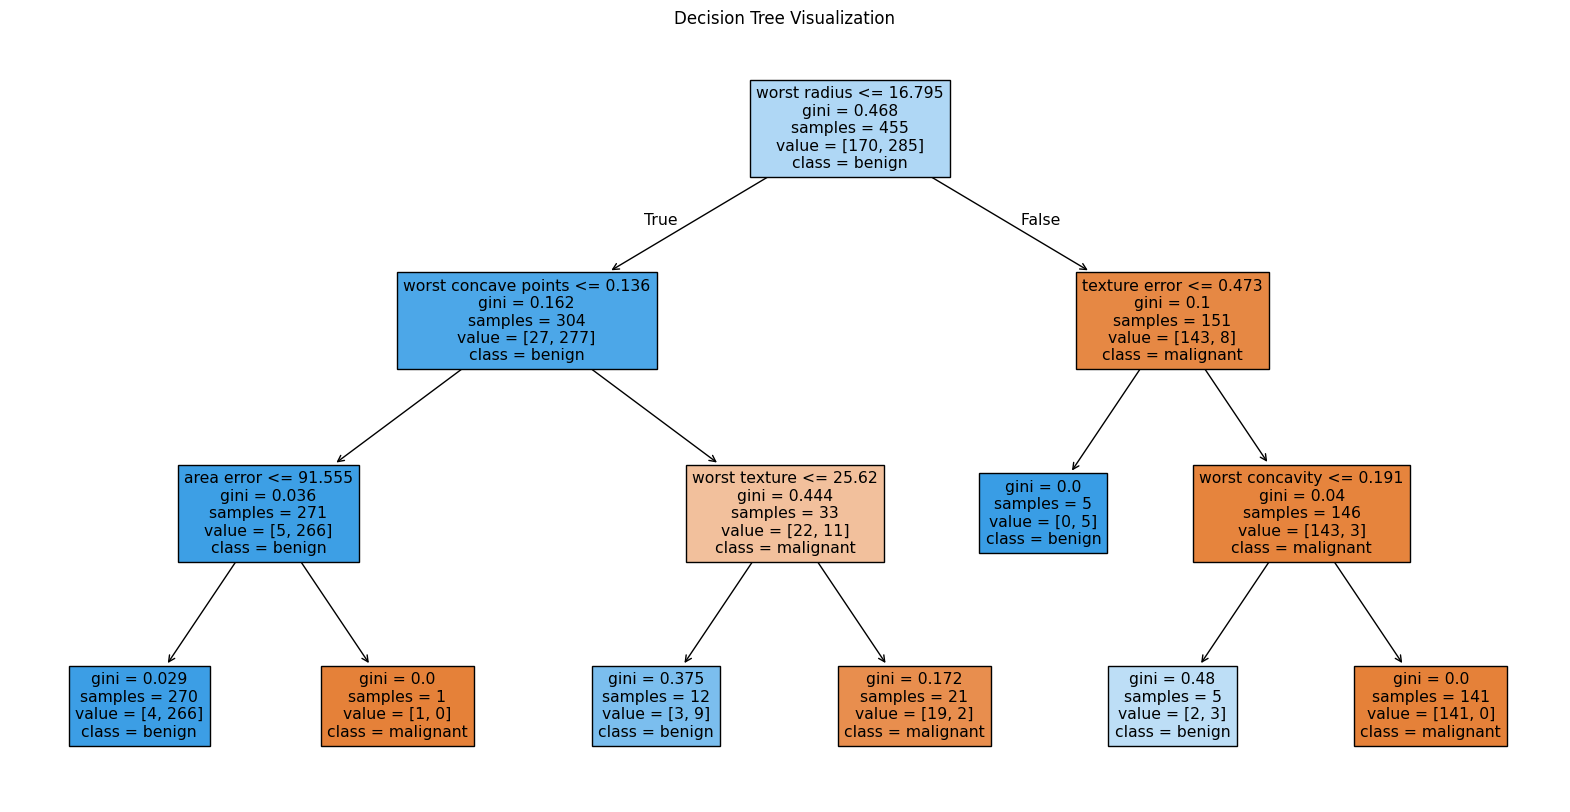

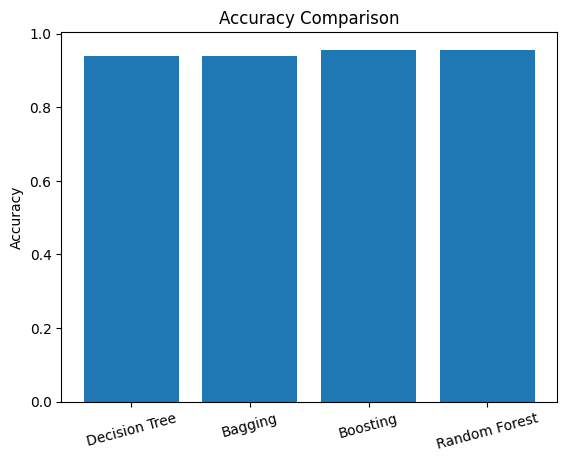

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Data
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("First 5 rows:\n", X.head())
print("\nShape:", X.shape)
print("\nClass Distribution:\n", pd.Series(y).value_counts())
print("\nTarget Classes:", data.target_names)

# Scatter Plot
plt.scatter(X.iloc[:,0], X.iloc[:,1], c=y, cmap="viridis")
plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Breast Cancer Dataset")
plt.show()

# Split Data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("\nTraining Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

# Models
models = {
    "Decision Tree": DecisionTreeClassifier(
        criterion="gini", max_depth=3, random_state=42),
    "Bagging": BaggingClassifier(n_estimators=50, random_state=42),
    "Boosting": AdaBoostClassifier(n_estimators=50, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

result = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    result.append([name, acc])

    print("\n", name)
    print("Accuracy:", acc)
    print(classification_report(y_test, y_pred))

# Accuracy Table
result = pd.DataFrame(result, columns=["Model", "Accuracy"])
print("\nACCURACY COMPARISON")
print(result)

# Decision Tree Plot
plt.figure(figsize=(20,10))
plot_tree(models["Decision Tree"], feature_names=data.feature_names,
          class_names=data.target_names, filled=True)
plt.title("Decision Tree Visualization")
plt.show()

# Accuracy Graph
plt.bar(result["Model"], result["Accuracy"])
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison")
plt.xticks(rotation=15)
plt.show()


# **Neural network**

Input data shape: (150, 4)
Target data shape: (150,)
Training samples: 120
Testing samples: 30

Activation Function: relu


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Test Accuracy: 90.0 %

Activation Function: sigmoid
Test Accuracy: 83.33 %

Activation Function: tanh
Test Accuracy: 96.67 %

===== ACTIVATION FUNCTION ACCURACY =====
relu : 90.0 %
sigmoid : 83.33 %
tanh : 96.67 %


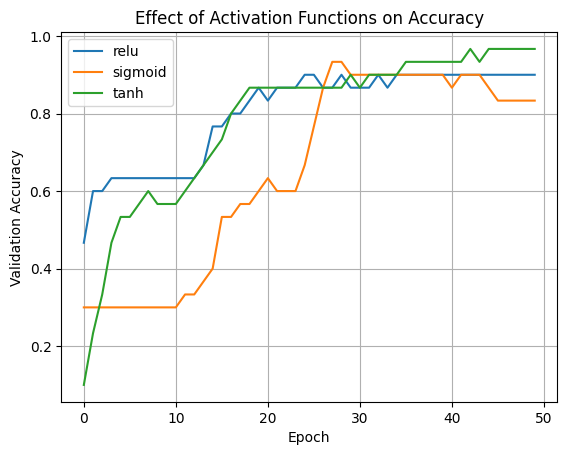


Loss Function: categorical_crossentropy
Test Accuracy: 100.0 %

Loss Function: kl_divergence
Test Accuracy: 96.67 %

===== LOSS FUNCTION ACCURACY =====
categorical_crossentropy : 100.0 %
kl_divergence : 96.67 %


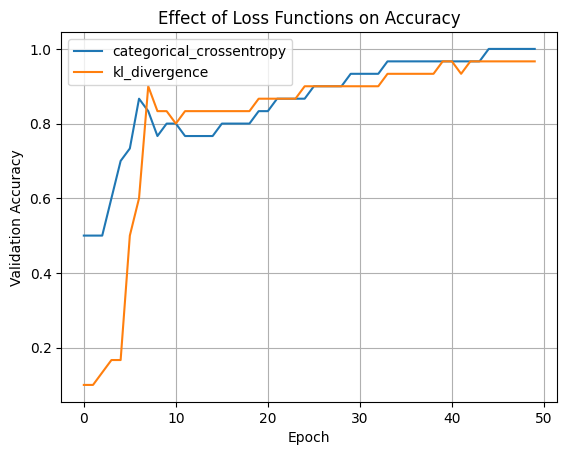

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical

# Load data
iris = load_iris()
X = iris.data
y = to_categorical(iris.target, 3)

print("Input data shape:", X.shape)
print("Target data shape:", iris.target.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# Create model
def create_model(act='relu', loss='categorical_crossentropy'):
    m = Sequential([
        Dense(10, activation=act, input_shape=(4,)),
        Dense(8, activation=act),
        Dense(3, activation='softmax')])
    m.compile(optimizer='adam', loss=loss, metrics=['accuracy'])
    return m

# Experiment 1: Activation functions
results = {}
for a in ['relu', 'sigmoid', 'tanh']:
    print("\nActivation Function:", a)
    m = create_model(act=a)
    h = m.fit(X_train, y_train, epochs=50, batch_size=10,
              validation_data=(X_test, y_test), verbose=0)
    _, acc = m.evaluate(X_test, y_test, verbose=0)
    results[a] = acc
    print("Test Accuracy:", round(acc * 100, 2), "%")
    plt.plot(h.history['val_accuracy'], label=a)

print("\n===== ACTIVATION FUNCTION ACCURACY =====")
for a, acc in results.items():
    print(a, ":", round(acc * 100, 2), "%")

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Effect of Activation Functions on Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Experiment 2: Loss functions
results = {}
for l in ['categorical_crossentropy', 'kl_divergence']:
    print("\nLoss Function:", l)
    m = create_model(loss=l)
    h = m.fit(X_train, y_train, epochs=50, batch_size=10,
              validation_data=(X_test, y_test), verbose=0)
    _, acc = m.evaluate(X_test, y_test, verbose=0)
    results[l] = acc
    print("Test Accuracy:", round(acc * 100, 2), "%")
    plt.plot(h.history['val_accuracy'], label=l)

print("\n===== LOSS FUNCTION ACCURACY =====")
for l, acc in results.items():
    print(l, ":", round(acc * 100, 2), "%")

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Effect of Loss Functions on Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# **NN with regularization**

Dataset shape: (208, 60)

Test Accuracy
----------------------------
Without Regularization : 0.857
Dropout                : 0.857
L2 Regularization      : 0.786


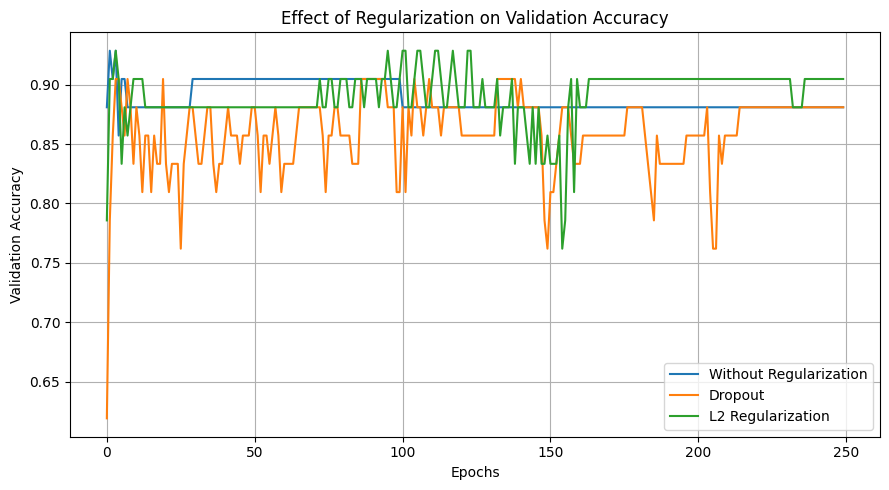

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Set random seed for reproducibility
tf.keras.utils.set_random_seed(42)

# Load Sonar dataset
data = fetch_openml(name='sonar', version=1, as_frame=False)
X = data.data
y = LabelEncoder().fit_transform(data.target)

print("Dataset shape:", X.shape)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# Feature Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Model 1: Without Regularization
model1 = keras.Sequential([
    layers.Input(shape=(60,)),
    layers.Dense(512, activation='relu', use_bias=True),
    layers.Dense(256, activation='relu', use_bias=True),
    layers.Dense(128, activation='relu', use_bias=True),
    layers.Dense(64, activation='relu', use_bias=True),
    layers.Dense(32, activation='relu', use_bias=True),
    layers.Dense(1, activation='sigmoid', use_bias=True)
])
model1.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Model 2: With Dropout Regularization
model2 = keras.Sequential([
    layers.Input(shape=(60,)),
    layers.Dense(512, activation='relu', use_bias=True),
    layers.Dropout(0.4),
    layers.Dense(256, activation='relu', use_bias=True),
    layers.Dropout(0.4),
    layers.Dense(128, activation='relu', use_bias=True),
    layers.Dropout(0.4),
    layers.Dense(64, activation='relu', use_bias=True),
    layers.Dense(32, activation='relu', use_bias=True),
    layers.Dense(1, activation='sigmoid', use_bias=True)
])
model2.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Model 3: With L2 Regularization
model3 = keras.Sequential([
    layers.Input(shape=(60,)),
    layers.Dense(512, activation='relu', use_bias=True, kernel_regularizer=regularizers.l2(0.001)),
    layers.Dense(256, activation='relu', use_bias=True, kernel_regularizer=regularizers.l2(0.001)),
    layers.Dense(128, activation='relu', use_bias=True, kernel_regularizer=regularizers.l2(0.001)),
    layers.Dense(64, activation='relu', use_bias=True, kernel_regularizer=regularizers.l2(0.001)),
    layers.Dense(32, activation='relu', use_bias=True, kernel_regularizer=regularizers.l2(0.001)),
    layers.Dense(1, activation='sigmoid', use_bias=True)
])
model3.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train all models
history1 = model1.fit(X_train, y_train, epochs=250, batch_size=8, validation_split=0.25, verbose=0)
history2 = model2.fit(X_train, y_train, epochs=250, batch_size=8, validation_split=0.25, verbose=0)
history3 = model3.fit(X_train, y_train, epochs=250, batch_size=8, validation_split=0.25, verbose=0)

# Evaluate model accuracies
_, acc1 = model1.evaluate(X_test, y_test, verbose=0)
_, acc2 = model2.evaluate(X_test, y_test, verbose=0)
_, acc3 = model3.evaluate(X_test, y_test, verbose=0)

# Print results
print("\nTest Accuracy")
print("----------------------------")
print("Without Regularization :", round(acc1, 3))
print("Dropout                :", round(acc2, 3))
print("L2 Regularization      :", round(acc3, 3))

# Plot Validation Accuracy Curves
plt.figure(figsize=(9, 5))
plt.plot(history1.history['val_accuracy'], label='Without Regularization')
plt.plot(history2.history['val_accuracy'], label='Dropout')
plt.plot(history3.history['val_accuracy'], label='L2 Regularization')

plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy")
plt.title("Effect of Regularization on Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# **HMM**

In [ ]:
!pip install hmmlearn

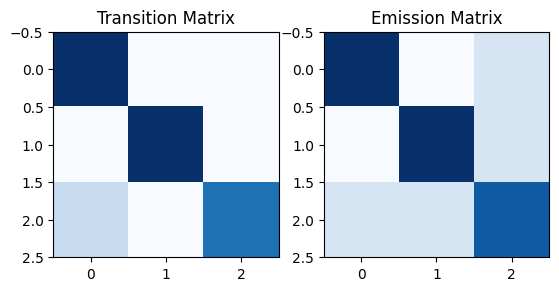

Observation Sequence: [0 1 2 0 1]
Predicted Weather: ['Rainy', 'Sunny', 'Cloudy', 'Rainy', 'Sunny']
Best Path Log Probability: -8.8861
Best Path Probability: 0.00013830


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from hmmlearn.hmm import CategoricalHMM

w = ['Rainy', 'Sunny', 'Cloudy']
m = CategoricalHMM(n_components=3)

m.startprob_ = np.array([0.4, 0.3, 0.3])
m.transmat_ = np.array([[0.6,0.2,0.2],
                        [0.2,0.6,0.2],
                        [0.3,0.2,0.5]])
m.emissionprob_ = np.array([[0.7,0.1,0.2],
                            [0.1,0.7,0.2],
                            [0.2,0.2,0.6]])

plt.subplot(1,2,1)
plt.imshow(m.transmat_, cmap='Blues')
plt.title('Transition Matrix')

plt.subplot(1,2,2)
plt.imshow(m.emissionprob_, cmap='Blues')
plt.title('Emission Matrix')
plt.show()

X = np.array([[0],[1],[2],[0],[1]])
p, s = m.decode(X, algorithm='viterbi')

print("Observation Sequence:", X.ravel())
print("Predicted Weather:", [w[i] for i in s])
print("Best Path Log Probability:", round(p,4))
print("Best Path Probability:", f"{np.exp(p):.8f}")


# **Q-learning**

Learned Policy:
 [['→' '→' '→' '↓']
 ['↑' 'X' '→' '↓']
 ['↑' '←' 'X' 'G']]


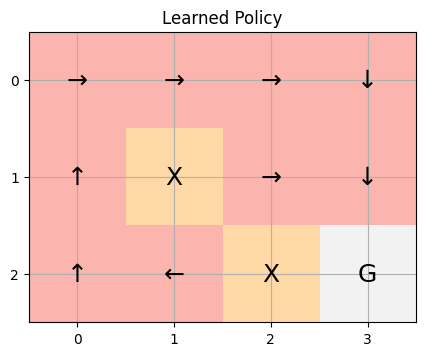

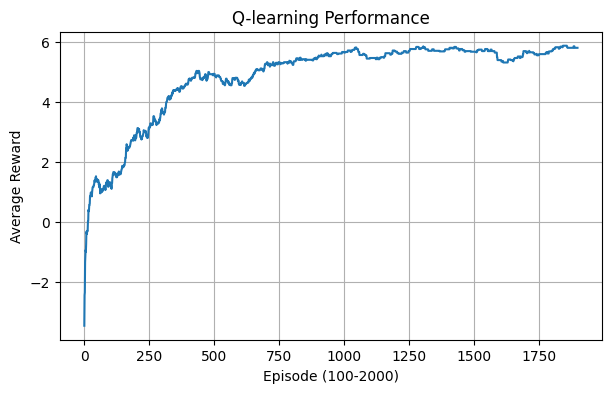

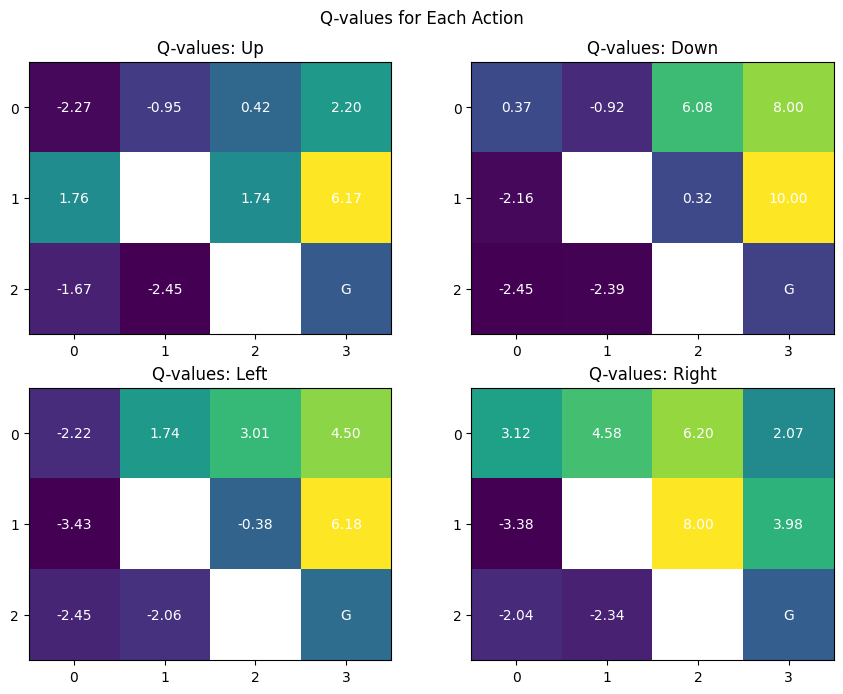


Q-values (Up, Down, Left, Right):
State (0, 0): [-2.27  0.37 -2.22  3.12]
State (0, 1): [-0.95 -0.92  1.74  4.58]
State (0, 2): [0.42 6.08 3.01 6.2 ]
State (0, 3): [2.2  8.   4.5  2.07]
State (1, 0): [ 1.76 -2.16 -3.43 -3.38]
State (1, 1): Obstacle
State (1, 2): [ 1.74  0.32 -0.38  8.  ]
State (1, 3): [ 6.17 10.    6.18  3.98]
State (2, 0): [-1.67 -2.45 -2.45 -2.04]
State (2, 1): [-2.45 -2.39 -2.06 -2.34]
State (2, 2): Obstacle
State (2, 3): Goal


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define the grid-world layout (0: Empty, 1: Obstacle, 2: Goal)
grid = np.array([[0, 0, 0, 0],
                 [0, 1, 0, 0],
                 [0, 0, 1, 2]])

rows, cols = grid.shape
Q = np.zeros((rows * cols, 4))
moves = [(-1, 0), (1, 0), (0, -1), (0, 1)]
arrows = ['↑', '↓', '←', '→']
names = ['Up', 'Down', 'Left', 'Right']

alpha, gamma, epsilon = 0.1, 0.9, 0.3
episodes, rewards = 2000, []

def step(state, action):
    r, c = divmod(state, cols)
    dr, dc = moves[action]
    nr, nc = r + dr, c + dc

    if not (0 <= nr < rows and 0 <= nc < cols) or grid[nr, nc] == 1:
        return state, -5, False
    if grid[nr, nc] == 2:
        return nr * cols + nc, 10, True
    return nr * cols + nc, -1, False

# Q-Learning Training Loop
for ep in range(episodes):
    state, total = 0, 0

    for _ in range(100):
        if np.random.random() < epsilon:
            action = np.random.randint(4)
        else:
            best = np.flatnonzero(Q[state] == Q[state].max())
            action = np.random.choice(best)

        nxt, reward, done = step(state, action)
        Q[state, action] += alpha * (
            reward + gamma * Q[nxt].max() * (not done) - Q[state, action]
        )

        state, total = nxt, total + reward
        if done:
            break

    rewards.append(total)
    epsilon = max(0.02, epsilon * 0.998)

# Extract learned policy
policy = np.full((rows, cols), " ", dtype=object)

for r in range(rows):
    for c in range(cols):
        if grid[r, c] == 1:
            policy[r, c] = 'X'
        elif grid[r, c] == 2:
            policy[r, c] = 'G'
        else:
            q = Q[r * cols + c]
            policy[r, c] = arrows[np.random.choice(np.flatnonzero(q == q.max()))]

print("Learned Policy:\n", policy)

# Plot Learned Policy Matrix
plt.figure(figsize=(5, 4))
plt.imshow(grid, cmap='Pastel1')
for r in range(rows):
    for c in range(cols):
        plt.text(c, r, policy[r, c], ha='center', va='center', fontsize=18)
plt.title("Learned Policy")
plt.xticks(range(cols)); plt.yticks(range(rows))
plt.grid(); plt.show()

# Plot Learning Performance Curve
plt.figure(figsize=(7, 4))
plt.plot(np.convolve(rewards, np.ones(100)/100, mode='valid'))
plt.xlabel("Episode (100-2000)")
plt.ylabel("Average Reward")
plt.title("Q-learning Performance")
plt.grid(); plt.show()

# Setup subplots for displaying Q-values of each action
fig, axes = plt.subplots(2, 2, figsize=(9, 7))

for a, ax in enumerate(axes.flat):
    values = Q[:, a].reshape(rows, cols).astype(float)
    values[grid == 1] = np.nan
    ax.imshow(values, cmap='viridis')

    for r in range(rows):
        for c in range(cols):
            label = 'X' if grid[r, c] == 1 else 'G' if grid[r, c] == 2 else f'{values[r,c]:.2f}'
            ax.text(c, r, label, ha='center', va='center', color='white')
    ax.set_title(f"Q-values: {names[a]}")
    ax.set_xticks(range(cols)); ax.set_yticks(range(rows))

plt.suptitle("Q-values for Each Action")
plt.tight_layout(); plt.show()

# Print state details
print("\nQ-values (Up, Down, Left, Right):")
for r in range(rows):
    for c in range(cols):
        state = r * cols + c
        result = "Obstacle" if grid[r, c] == 1 else "Goal" if grid[r, c] == 2 else np.round(Q[state], 2)
        print(f"State ({r}, {c}): {result}")